<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/RNN_P7_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# From Simple RNNs to LSTM

We have seen that a simple RNN carries information forward through its hidden state:

$$
h_t = f(x_t, h_{t-1})
$$

This gives the RNN **memory**, but there is an important limitation:

> As the sequence becomes longer, information from much earlier time steps can become difficult to preserve and learn.

During Backpropagation Through Time, gradients must travel through many recurrent steps:


# Long Short-Term Memory (LSTM)


Gradient clipping can help with **exploding gradients**, but it does **not** solve the vanishing-gradient problem.

LSTM was designed to improve this by adding a more controlled memory mechanism.

Instead of relying only on the hidden state, an LSTM introduces a **cell state** that can carry information across many time steps.



It also uses gates to control that memory:

- **Forget gate** → decides what old information to remove/What old information should I keep/remove?
- **Input gate** → decides what new information to store/What new information should I add to memory?
- **Output gate** → decides what information to reveal/What part of my memory is useful right now?

Conceptually:

`previous memory + current input → gates → updated memory → hidden state/output`

> **Key idea:** LSTM helps an RNN preserve important information for longer periods by learning what to **forget, remember, and output**.


Instead of relying only on the hidden state, LSTM maintains:

- a **cell state** for longer-term memory,
- a **hidden state** for the information currently being used.

The key idea is that information can move through the cell state more directly, making it easier to preserve useful information and gradients over long sequences.

Conceptually:

`simple RNN → hidden state only`

`LSTM → cell state + hidden state`

> **Key idea:** LSTM extends the RNN with a dedicated memory mechanism so that important information can be preserved for longer periods of time.

## LSTM: Learning What to Keep, Change, and Use

The major difference between a **simple RNN** and an **LSTM** is that the LSTM can **control the flow of information** instead of simply updating its state at every time step.


At time step $t$, the LSTM uses:

- the **current input** $X_t$
- the **previous hidden state** $H_{t-1}$

to compute three gates.




### The Three Gates

**Input gate**

$$
I_t = \sigma(X_t W_{xi} + H_{t-1} W_{hi} + b_i)
$$

**Forget gate**

$$
F_t = \sigma(X_t W_{xf} + H_{t-1} W_{hf} + b_f)
$$

**Output gate**

$$
O_t = \sigma(X_t W_{xo} + H_{t-1} W_{ho} + b_o)
$$


### What Are These Formulas Doing?

All three gates look at the same two sources of information:

$$
\text{current input } X_t
\quad + \quad
\text{previous hidden state } H_{t-1}
$$

but each gate has its **own learned weights**, so each gate learns a different decision:

- **Forget gate $F_t$** → What old information should I keep or forget?
- **Input gate $I_t$** → How much new information should I allow into memory?
- **Output gate $O_t$** → How much of the current memory should I use right now?



### Why Sigmoid?

Each gate uses the sigmoid function:

$$
\sigma(z) \in (0,1)
$$

Therefore, each gate behaves like a **learned filter**:

`0 → block` &nbsp;&nbsp;&nbsp; `0.5 → partially allow` &nbsp;&nbsp;&nbsp; `1 → allow`



This makes the sigmoid output behave naturally like a **soft gate**:

- value near **0** → block or ignore the information
- value near **1** → allow the information through
- value between **0 and 1** → allow part of the information through



The gate values are **not chosen manually**. During training, the LSTM learns the weight matrices $W$, allowing the gates to learn when information should be **forgotten, added, or used**.

> **Key idea:** $X_t$ tells the gates what is happening **now**, while $H_{t-1}$ provides information about what happened **before**. Together, they help the LSTM decide how to manage its memory.

### LSTM Gate Diagram

At each time step $t$, **the same two pieces of information are sent to all three gates**:

- $X_t$ → the **current input**
- $H_{t-1}$ → the **previous hidden state**

The diagram shows these two values being **copied and combined** before being sent to three separate fully connected layers:

$$
X_t,\;H_{t-1}
\longrightarrow
\begin{cases}
\text{Forget gate } F_t\\
\text{Input gate } I_t\\
\text{Output gate } O_t
\end{cases}
$$



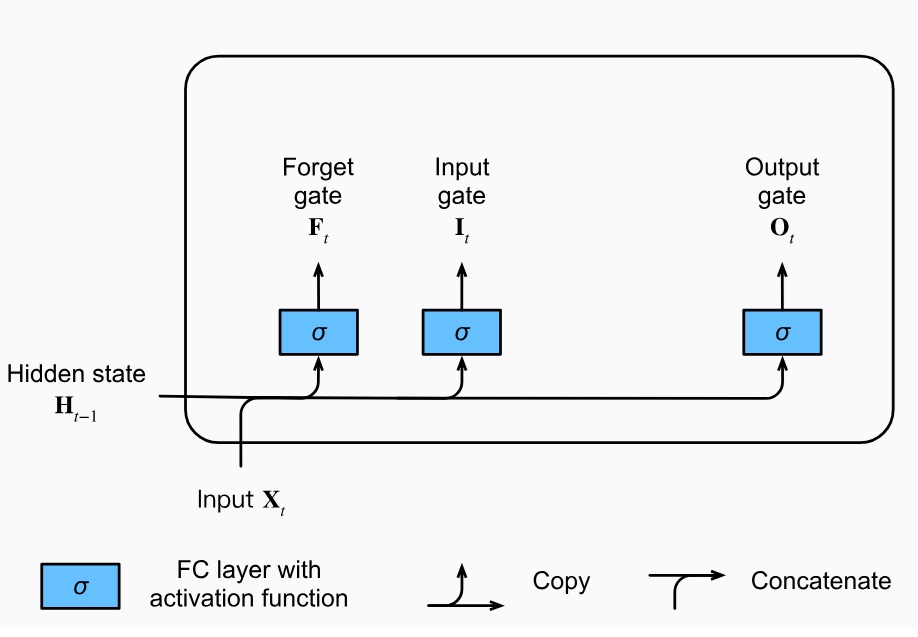

Although the gates receive the **same inputs**, they have **different learned weights**, so they can learn different decisions:

- $F_t$ → **What old information should be kept?**
- $I_t$ → **What new information should be allowed into memory?**
- $O_t$ → **What stored information should be used now?**

Each blue $\sigma$ block represents a **fully connected layer followed by sigmoid**. Sigmoid produces values between 0 and 1, allowing each gate to control **how much** information passes through.

> **Important:** This figure only shows how the **gate values** $F_t$, $I_t$, and $O_t$ are calculated. The next step is to see how these gates actually modify the LSTM's memory.

## LSTM Input Node: Creating New Candidate Information

We already have three **gates** that control information flow.  
But before the input gate can decide what to add to memory, the LSTM needs to create the **new information that could be added**.

This is the job of the **input node**, also called the **candidate memory**:

$$
\tilde{C}_t = \tanh(X_t W_{xc} + H_{t-1} W_{hc} + b_c)
$$





### What Does This Formula Mean?

The input node looks at:

- $X_t$ → the **current input**
- $H_{t-1}$ → the **previous hidden state**

and combines them using learned weights:

$$
X_t W_{xc} + H_{t-1} W_{hc} + b_c
$$

Then `tanh` transforms the result:

$$
-1 < \tilde{C}_t < 1
$$

So $\tilde{C}_t$ represents:

> **"Based on what I see now and what I knew before, what new information could be stored in memory?"**

### Why `tanh` Instead of Sigmoid?

The **gates** use sigmoid because they control **how much information passes**:

$$
0 < I_t,F_t,O_t < 1
$$

The input node has a different job. It creates **candidate content**, so it uses `tanh`:

$$
-1 < \tilde{C}_t < 1
$$

This allows the candidate information to contain both **positive and negative values**.

### Input Gate vs. Input Node

These two have different jobs:

$$
\underbrace{\tilde{C}_t}_{\text{What new information is available?}}
\qquad
\underbrace{I_t}_{\text{How much of it should be stored?}}
$$

They will soon work together:

$$
I_t \odot \tilde{C}_t
$$

The input gate $I_t$ acts as a filter on the candidate memory $\tilde{C}_t$.

> **Key idea:** The **input node creates candidate information**; the **input gate decides how much of that information is allowed into the LSTM's memory**.

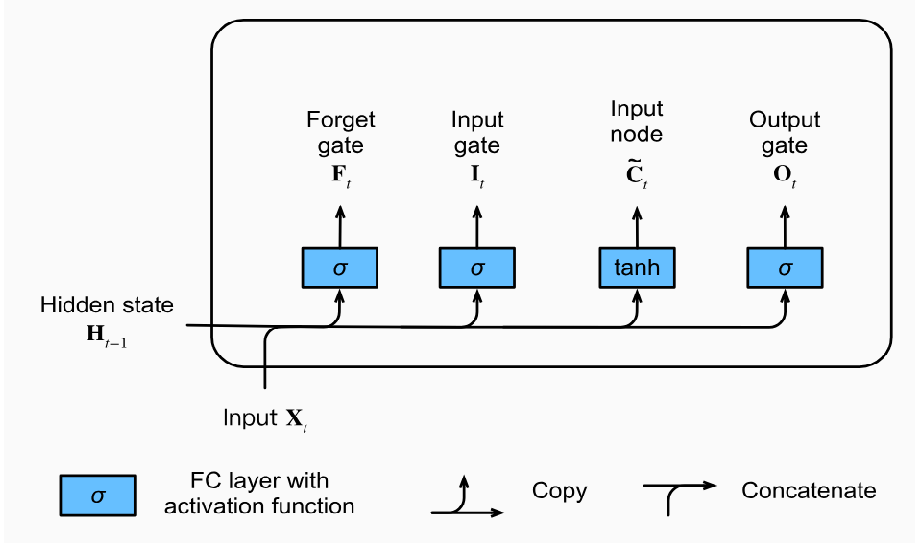

## LSTM: Updating the Memory Cell

Now we can see how the LSTM updates its **cell state** $C_t$ — its internal memory.

The update equation is:

$$
C_t = F_t \odot C_{t-1} + I_t \odot \tilde{C}_t
$$

This can be read very simply as:

$$
\boxed{\text{New Memory} = \text{Kept Old Memory} + \text{Selected New Information}}
$$

### 1. Decide What Old Memory to Keep

$$
F_t \odot C_{t-1}
$$

- $C_{t-1}$ = memory from the previous time step
- $F_t$ = forget gate, with values between 0 and 1

The forget gate controls how much of the old memory survives:

`0 → forget it` &nbsp;&nbsp; `1 → keep it` &nbsp;&nbsp; `0.5 → keep half`

So:

$$
F_t \odot C_{t-1}
=
\text{old information we decided to keep}
$$


### 2. Decide What New Information to Add

$$
I_t \odot \tilde{C}_t
$$

Here the two components we discussed earlier work together:

- $\tilde{C}_t$ → **what new information could be stored**
- $I_t$ → **how much of that new information should actually be stored**

Therefore:

$$
I_t \odot \tilde{C}_t
=
\text{selected new information}
$$


### 3. Combine Them

The LSTM adds the two pieces:

$$
\underbrace{F_t \odot C_{t-1}}_{\text{keep from old memory}}
+
\underbrace{I_t \odot \tilde{C}_t}_{\text{add from new information}}
=
\underbrace{C_t}_{\text{updated memory}}
$$


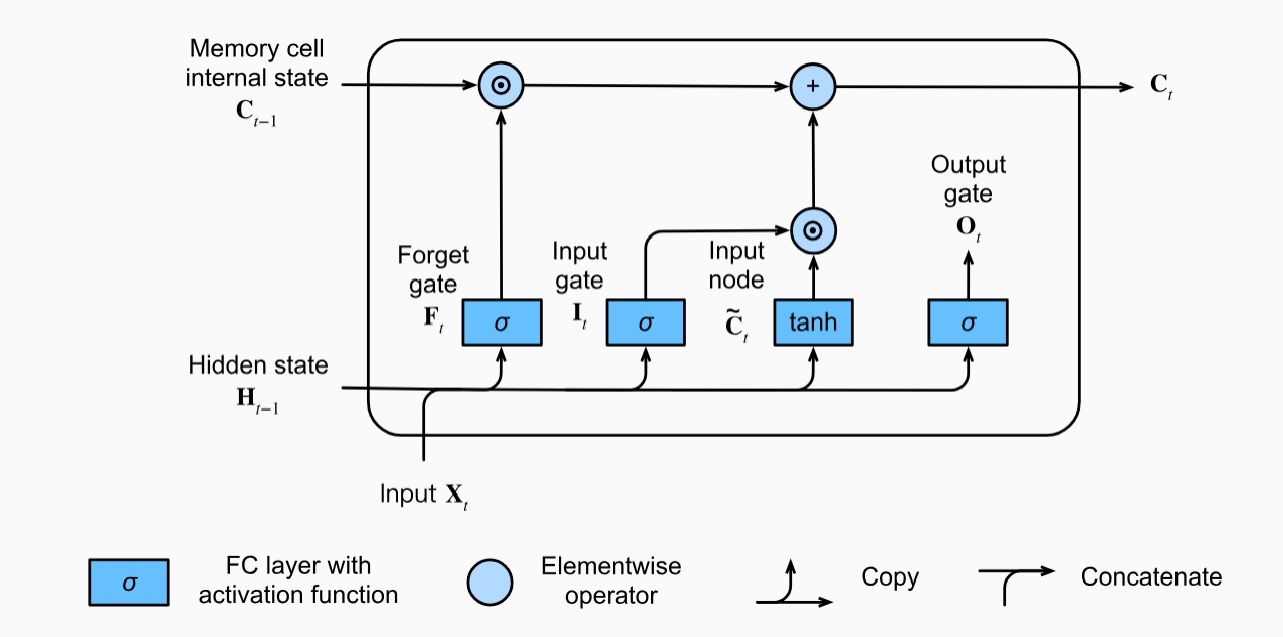

Conceptually:

`Old Memory → Forget Gate → Keep useful parts`

`New Candidate → Input Gate → Accept useful parts`

`Kept Old + Accepted New → New Memory`



### Why Is This Important for Long-Term Memory?

Suppose the LSTM decides that some information should remain unchanged:

$$
F_t \approx 1
\qquad\text{and}\qquad
I_t \approx 0
$$

Then:

$$
C_t \approx C_{t-1}
$$

The memory can therefore pass from one time step to the next with very little change.

This more direct path through the cell state also gives gradients a better path through many time steps, helping reduce the **vanishing-gradient problem** that simple RNNs struggle with.

> **Key idea:** LSTM memory is updated by **keeping selected old information and adding selected new information**.

## LSTM: Computing the Hidden State

At this point, the LSTM has already updated its internal memory:

$$
C_t = F_t \odot C_{t-1} + I_t \odot \tilde{C}_t
$$

But the LSTM does **not necessarily use all of this memory right now**.





The **output gate** decides which parts of the current memory should influence the hidden state:

$$
H_t = O_t \odot \tanh(C_t)
$$



### What Is Happening?

First, the updated memory passes through `tanh`:

$$
\tanh(C_t)
$$

This maps the memory to values between $-1$ and $1$, producing a controlled version of the cell state.

Then the **output gate** $O_t$ acts as a filter:

$$
\underbrace{O_t}_{\text{how much to use}}
\odot
\underbrace{\tanh(C_t)}_{\text{current memory}}
=
\underbrace{H_t}_{\text{hidden state}}
$$

Because $O_t$ contains values between 0 and 1:

- $O_t \approx 0$ → that information stays in memory but has little effect **right now**
- $O_t \approx 1$ → that information strongly influences the hidden state
- values in between → partially use the information

### Why Have Both $C_t$ and $H_t$?

This is an important feature of LSTM:

- $C_t$ → **internal memory** that can carry information across many time steps
- $H_t$ → **information from that memory that is useful at the current time step**

So the LSTM can **remember something without having to use it immediately**.



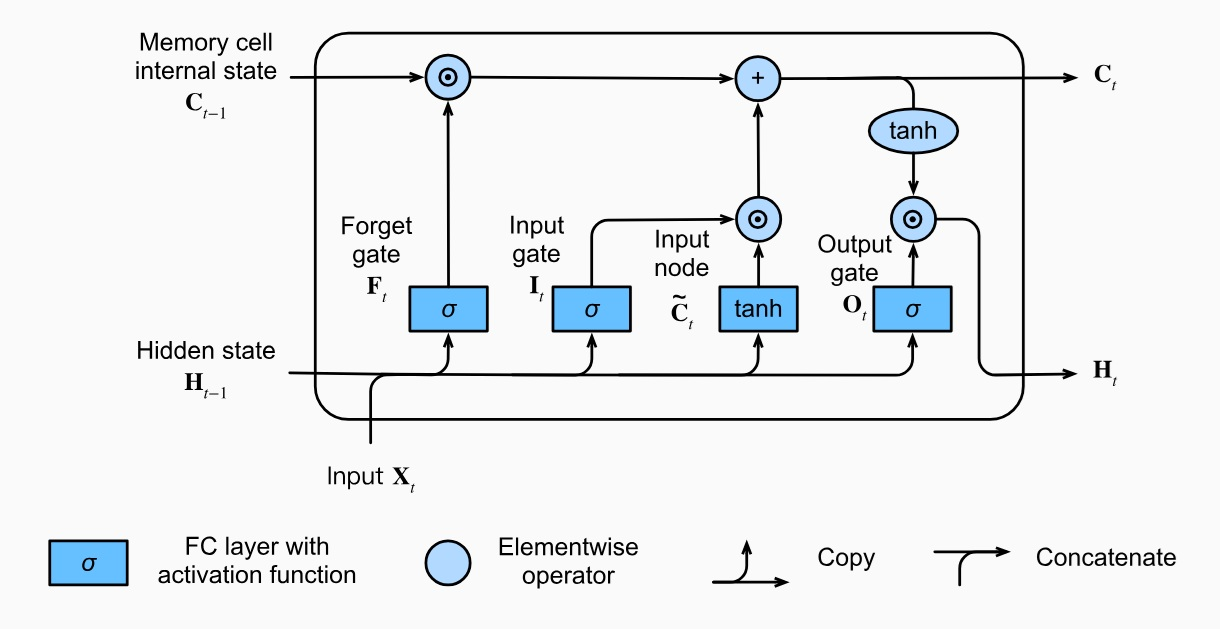

### The Complete LSTM Memory Flow

We can now put the major pieces together:

$$
\boxed{
C_t =
F_t \odot C_{t-1}
+
I_t \odot \tilde{C}_t
}
$$

$$
\boxed{
H_t =
O_t \odot \tanh(C_t)
}
$$

In words:

**Forget some old memory → add selected new information → update the memory → select what to use now**



> **Key idea:** $C_t$ answers **"What do I remember?"**, while $H_t$ answers **"What part of what I remember should I use right now?"**